In [1]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import re
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB # NB model
from sklearn.metrics import classification_report, confusion_matrix # assessment tool
from sklearn.linear_model import LogisticRegression # LR model

import numpy as np

In [2]:
!pip install imbalanced-learn
from imblearn.over_sampling import SMOTE

Defaulting to user installation because normal site-packages is not writeable


In [3]:
df=pd.read_csv("tweet_emotions.csv")
df

,tweet_id,sentiment,content
0,1956967341,empty,@tiffanylue i know i was listenin to bad habi...
1,1956967666,sadness,Layin n bed with a headache ughhhh...waitin o...
2,1956967696,sadness,Funeral ceremony...gloomy friday...
3,1956967789,enthusiasm,wants to hang out with friends SOON!
4,1956968416,neutral,@dannycastillo We want to trade with someone w...
...,...,...,...
39995,1753918954,neutral,@JohnLloydTaylor
39996,1753919001,love,Happy Mothers Day All my love
39997,1753919005,love,Happy Mother's Day to all the mommies out ther...
39998,1753919043,happiness,@niariley WASSUP BEAUTIFUL!!! FOLLOW ME!! PEE...


In [4]:
df["sentiment"].value_counts()

neutral       8638
worry         8459
happiness     5209
sadness       5165
love          3842
surprise      2187
fun           1776
relief        1526
hate          1323
empty          827
enthusiasm     759
boredom        179
anger          110
Name: sentiment, dtype: int64

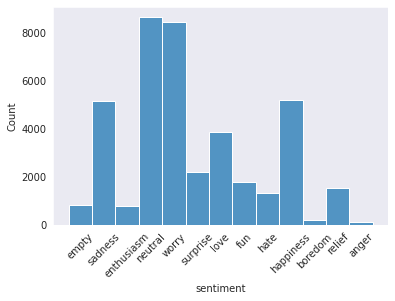

In [5]:
pd.plotting.register_matplotlib_converters()
sns.set_style("dark")
sns.histplot(df['sentiment'])
plt.xticks(rotation=45) 
plt.show()

In [6]:
# cleaning text
# Keep 'sentiment' set to 'empty' until the next step

df["cleaned_text"] = df["content"].apply(lambda x: re.sub(r"@[\\w]*", "", str(x))) # symbols
df["cleaned_text"] = df["cleaned_text"].apply(lambda x: re.sub(r"[^a-zA-Z']", " ", x)) #lowercase & '
df["cleaned_text"] = df["cleaned_text"].str.lower().str.strip() 

# remove "empty" and too short text
df_cleaned = df[df['sentiment'] != 'empty'].copy()
df_cleaned = df_cleaned[df_cleaned["cleaned_text"].str.len() > 1].reset_index(drop=True) 

print(f"Origin lines: {len(df)}")
print(f"After cleaning:: {len(df_cleaned)}")
df_cleaned.head()

Origin lines: 40000
After cleaning:: 39170


,tweet_id,sentiment,content,cleaned_text
0,1956967666,sadness,Layin n bed with a headache ughhhh...waitin o...,layin n bed with a headache ughhhh waitin o...
1,1956967696,sadness,Funeral ceremony...gloomy friday...,funeral ceremony gloomy friday
2,1956967789,enthusiasm,wants to hang out with friends SOON!,wants to hang out with friends soon
3,1956968416,neutral,@dannycastillo We want to trade with someone w...,dannycastillo we want to trade with someone wh...
4,1956968477,worry,Re-pinging @ghostridah14: why didn't you go to...,re pinging ghostridah why didn't you go to ...


In [7]:
# 统计清洗后各情感类别的数量
sentiment_counts_cleaned = df_cleaned['sentiment'].value_counts()

print("Emotion Distribution after cleaning:")
print(sentiment_counts_cleaned)

Emotion Distribution after cleaning:
neutral       8635
worry         8459
happiness     5209
sadness       5165
love          3842
surprise      2187
fun           1776
relief        1526
hate          1323
enthusiasm     759
boredom        179
anger          110
Name: sentiment, dtype: int64


In [8]:
# feature:x label: y
X = df_cleaned['cleaned_text']
y = df_cleaned['sentiment']

# encode
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# save class names
class_names = le.classes_ 

print("Label and Code comparison table:")
for i, name in enumerate(class_names):
    print(f"{i}: {name}")

Label and Code comparison table:
0: anger
1: boredom
2: enthusiasm
3: fun
4: happiness
5: hate
6: love
7: neutral
8: relief
9: sadness
10: surprise
11: worry


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y_encoded, 
    test_size=0.2, 
    random_state=42, 
    stratify=y_encoded 
)

# Stratified sampling ensures that the proportion of categories in the training set and the test set is consistent

print(f"The sample size of the training set: {len(X_train)}")
print(f"The sample size of the testing set: {len(X_test)}")

The sample size of the training set: 31336
The sample size of the testing set: 7834


In [10]:
# max_features=10000: consider top 10000 words as features
# ngram_range=(1, 2): consider unigram & bigram
tfidf_vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1, 2),stop_words='english')

# fit model
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print(f"Shape of training set features matrix(sample, features): {X_train_tfidf.shape}")
print(f"Shape of testing set features matrix(sample, features): {X_test_tfidf.shape}")

Shape of training set features matrix(sample, features): (31336, 10000)
Shape of testing set features matrix(sample, features): (7834, 10000)


In [11]:
# import Multinomial NB model
mnb_model = MultinomialNB()
mnb_model.fit(X_train_tfidf, y_train)

y_pred = mnb_model.predict(X_test_tfidf)

--- Classification report ---
              precision    recall  f1-score   support

       anger       0.00      0.00      0.00        22
     boredom       0.00      0.00      0.00        36
  enthusiasm       0.00      0.00      0.00       152
         fun       0.50      0.00      0.01       355
   happiness       0.35      0.23      0.28      1042
        hate       0.00      0.00      0.00       265
        love       0.53      0.23      0.32       768
     neutral       0.30      0.55      0.39      1727
      relief       0.00      0.00      0.00       305
     sadness       0.36      0.09      0.15      1033
    surprise       0.00      0.00      0.00       437
       worry       0.30      0.59      0.40      1692

    accuracy                           0.32      7834
   macro avg       0.19      0.14      0.13      7834
weighted avg       0.30      0.32      0.26      7834



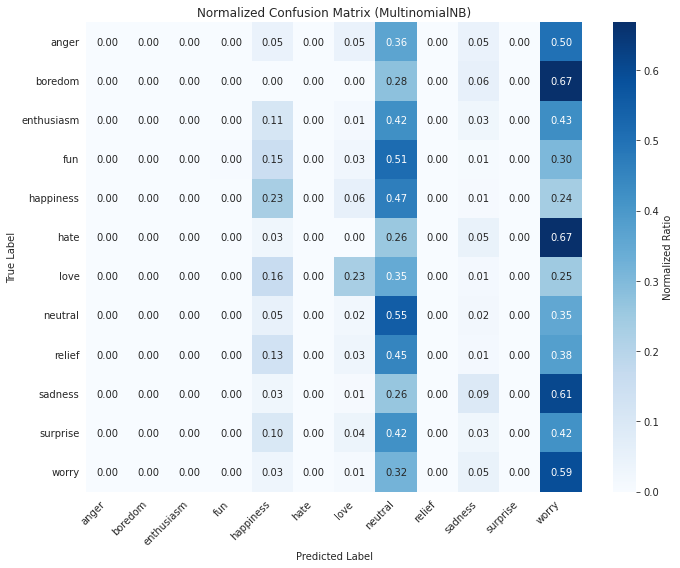

In [12]:
print("--- Classification report ---")
print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))

# generating confusion matrix
cm = confusion_matrix(y_test, y_pred)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] # 归一化

# visualization
plt.figure(figsize=(10, 8))  
sns.heatmap(
    cm_normalized, 
    annot=True, 
    fmt=".2f", 
    cmap="Blues",
    xticklabels=class_names, 
    yticklabels=class_names,
    cbar_kws={"label": "Normalized Ratio"} 
)
plt.title('Normalized Confusion Matrix (MultinomialNB)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout() 
plt.show()

In [13]:
#Laplace smoothing: calculating different alpha to get best situation
alpha_list = [0.01, 0.1, 0.5, 1.0, 2.0]
for alpha in alpha_list:
    temp_model = MultinomialNB(alpha=alpha)
    temp_model.fit(X_train_tfidf, y_train)
    temp_pred = temp_model.predict(X_test_tfidf)
    accuracy = (temp_pred == y_test).mean()
    print(f"alpha={alpha} ，accuracy：{accuracy:.4f}")

alpha=0.01 ，accuracy：0.3113
alpha=0.1 ，accuracy：0.3166
alpha=0.5 ，accuracy：0.3213
alpha=1.0 ，accuracy：0.3158
alpha=2.0 ，accuracy：0.3141


--- Classification report（alpha=0.5） ---
              precision    recall  f1-score   support

       anger       0.00      0.00      0.00        22
     boredom       0.00      0.00      0.00        36
  enthusiasm       0.00      0.00      0.00       152
         fun       0.25      0.00      0.01       355
   happiness       0.33      0.27      0.29      1042
        hate       0.60      0.01      0.02       265
        love       0.47      0.26      0.34       768
     neutral       0.31      0.54      0.39      1727
      relief       0.00      0.00      0.00       305
     sadness       0.35      0.16      0.22      1033
    surprise       0.25      0.00      0.00       437
       worry       0.30      0.55      0.39      1692

    accuracy                           0.32      7834
   macro avg       0.24      0.15      0.14      7834
weighted avg       0.32      0.32      0.27      7834



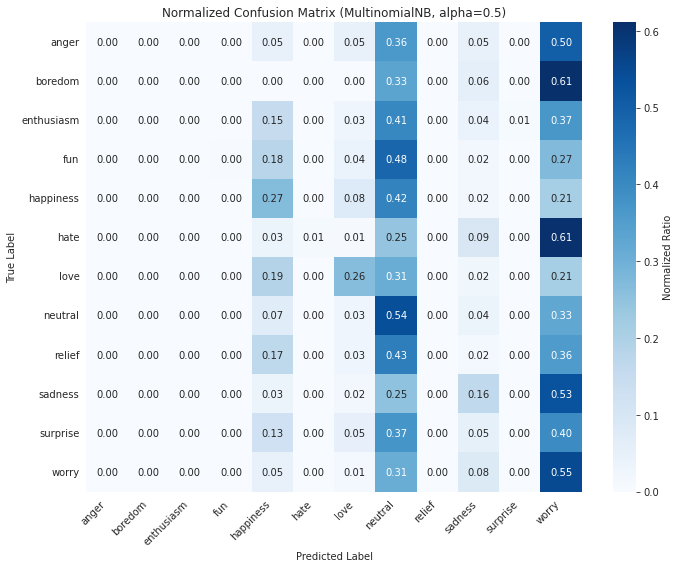

In [14]:
#alpha = 0.5 has best accuracy
mnb_model = MultinomialNB(alpha=0.5)

mnb_model.fit(X_train_tfidf, y_train)

y_pred = mnb_model.predict(X_test_tfidf)


print("--- Classification report（alpha=0.5） ---")
print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))

cm = confusion_matrix(y_test, y_pred)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(10, 8))  
sns.heatmap(
    cm_normalized, 
    annot=True, 
    fmt=".2f", 
    cmap="Blues",
    xticklabels=class_names, 
    yticklabels=class_names,
    cbar_kws={"label": "Normalized Ratio"}  # 新增色条标签，更清晰
)
plt.title('Normalized Confusion Matrix (MultinomialNB, alpha=0.5)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()  # 自动调整布局，避免标签被截断
plt.show()

In [15]:
# Initialize SMOTE
smote = SMOTE(
    random_state=42,
    sampling_strategy='not majority',
    k_neighbors=5
)

# Apply SMOTE to training set ONLY
print("📈 Class distribution BEFORE SMOTE:")
train_dist = pd.Series(y_train).value_counts().sort_index()
for idx, cnt in train_dist.items():
    print(f"  {class_names[idx]}: {cnt}")

X_train_tfidf_smote, y_train_smote = smote.fit_resample(X_train_tfidf, y_train)

print("\n📈 Class distribution AFTER SMOTE:")
train_dist_smote = pd.Series(y_train_smote).value_counts().sort_index()
for idx, cnt in train_dist_smote.items():
    print(f"  {class_names[idx]}: {cnt}")

print(f"\n✅ SMOTE applied - New training shape: {X_train_tfidf_smote.shape}")

📈 Class distribution BEFORE SMOTE:
  anger: 88
  boredom: 143
  enthusiasm: 607
  fun: 1421
  happiness: 4167
  hate: 1058
  love: 3074
  neutral: 6908
  relief: 1221
  sadness: 4132
  surprise: 1750
  worry: 6767

📈 Class distribution AFTER SMOTE:
  anger: 6908
  boredom: 6908
  enthusiasm: 6908
  fun: 6908
  happiness: 6908
  hate: 6908
  love: 6908
  neutral: 6908
  relief: 6908
  sadness: 6908
  surprise: 6908
  worry: 6908

✅ SMOTE applied - New training shape: (82896, 10000)


In [16]:
# Train Logistic Regression with balanced weights
lr_model = LogisticRegression(
    max_iter=2000,
    C=0.5,
    random_state=42
)

# Fit model
lr_model.fit(X_train_tfidf_smote, y_train_smote)

# Predict on test set
y_pred = lr_model.predict(X_test_tfidf)

In [17]:
# Generate classification report
report = classification_report(
    y_test, 
    y_pred, 
    target_names=class_names, 
    zero_division=0,
    output_dict=True
)

# Print formatted report
print("📊 Classification Report (Logistic Regression + SMOTE)\n")
# Convert to DataFrame for better display in Notebook
report_df = pd.DataFrame(report).transpose()
report_df = report_df.round(4)  # Round to 4 decimal places
display(report_df)  

📊 Classification Report (Logistic Regression + SMOTE)



,precision,recall,f1-score,support
anger,0.0000,0.0000,0.0000,22.0000
boredom,0.0496,0.1944,0.0791,36.0000
enthusiasm,0.0182,0.0724,0.0291,152.0000
fun,0.1241,0.2000,0.1532,355.0000
happiness,0.3517,0.3119,0.3306,1042.0000
hate,0.1921,0.3283,0.2423,265.0000
love,0.4448,0.4141,0.4289,768.0000
neutral,0.3463,0.2119,0.2629,1727.0000
relief,0.1148,0.1836,0.1412,305.0000
sadness,0.3180,0.2682,0.2910,1033.0000


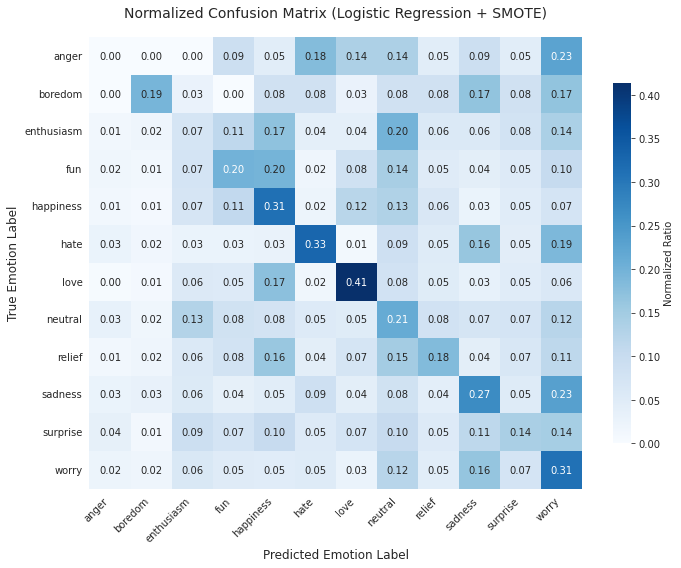

In [18]:
# Generate and normalize confusion matrix
cm = confusion_matrix(y_test, y_pred)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# Plot heatmap
plt.figure(figsize=(10, 8))
ax = sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={"label": "Normalized Ratio", "shrink": 0.8}
)

# Customize plot
plt.title('Normalized Confusion Matrix (Logistic Regression + SMOTE)', fontsize=14, pad=20)
plt.ylabel('True Emotion Label', fontsize=12)
plt.xlabel('Predicted Emotion Label', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

# Show plot
plt.show()

In [19]:

negative_emotions = ['worry', 'sadness', 'hate', 'boredom', 'anger']
positive_emotions = [emo for emo in class_names if emo not in negative_emotions + ['neutral']]

print("Negative emotions:", negative_emotions)
print("Positive emotions:", positive_emotions)

# Filter out the neutral samples 
df_binary = df_cleaned[df_cleaned['sentiment'] != 'neutral'].copy()

# generate binary classification label
df_binary['binary_label'] = df_binary['sentiment'].apply(
    lambda x: 1 if x in positive_emotions else 0
)

print("\nBinary classification sample distribution (original):")
bin_dist = df_binary['binary_label'].value_counts()
print(bin_dist)
print(f"Positive samples: {len(df_binary[df_binary['binary_label']==1])}")
print(f"Negative samples: {len(df_binary[df_binary['binary_label']==0])}")#The closer it is to 1, the more balanced it is
X_binary = df_binary['cleaned_text']  
y_binary = df_binary['binary_label'] 

X_train_bin, X_test_bin, y_train_bin, y_test_bin = train_test_split(
    X_binary, y_binary, test_size=0.2, random_state=42, stratify=y_binary
)

tfidf_bin = TfidfVectorizer(max_features=10000, ngram_range=(1,2))

X_train_tfidf_bin = tfidf_bin.fit_transform(X_train_bin)

X_test_tfidf_bin = tfidf_bin.transform(X_test_bin)


print(f"Training set feature：{X_train_tfidf_bin.shape}")
print(f"Testing set feature：{X_test_tfidf_bin.shape}")

lr_binary = LogisticRegression(
    class_weight='balanced',
    max_iter=2000,
    C=0.5, 
    random_state=42
)

lr_binary.fit(X_train_tfidf_bin, y_train_bin)

y_pred_bin = lr_binary.predict(X_test_tfidf_bin)


Negative emotions: ['worry', 'sadness', 'hate', 'boredom', 'anger']
Positive emotions: ['enthusiasm', 'fun', 'happiness', 'love', 'relief', 'surprise']

Binary classification sample distribution (original):
1    15299
0    15236
Name: binary_label, dtype: int64
Positive samples: 15299
Negative samples: 15236
Training set feature：(24428, 10000)
Testing set feature：(6107, 10000)



--- Evaluation results ---
Accuracy: 0.7472

Classification report:
              precision    recall  f1-score   support

    Negative       0.74      0.77      0.75      3047
    Positive       0.76      0.73      0.74      3060

    accuracy                           0.75      6107
   macro avg       0.75      0.75      0.75      6107
weighted avg       0.75      0.75      0.75      6107



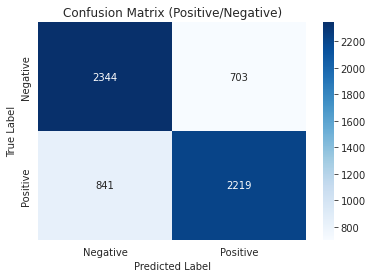

In [20]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("\n--- Evaluation results ---")
print(f"Accuracy: {accuracy_score(y_test_bin, y_pred_bin):.4f}")
print("\nClassification report:")
print(classification_report(y_test_bin, y_pred_bin, target_names=['Negative', 'Positive']))

cm_bin = confusion_matrix(y_test_bin, y_pred_bin)
plt.figure(figsize=(6,4))
sns.heatmap(
    cm_bin, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)
plt.title('Confusion Matrix (Positive/Negative)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

In [21]:
!pip install xgboost -i https://mirrors.aliyun.com/pypi/simple/

Defaulting to user installation because normal site-packages is not writeable
Looking in indexes: https://mirrors.aliyun.com/pypi/simple/


In [22]:
!pip install lightgbm --only-binary :all: -i https://pypi.tuna.tsinghua.edu.cn/simple/

Defaulting to user installation because normal site-packages is not writeable
Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple/


In [24]:
# 导入必要的库
import xgboost as xgb
from sklearn.metrics import accuracy_score, classification_report

# ====================== 训练XGBoost模型（单独版本） ======================
print("===== XGBoost模型 =====")
# 初始化XGBoost分类器（二分类任务配置）
xgb_model = xgb.XGBClassifier(
    objective='binary:logistic',  # 二分类任务的目标函数
    n_estimators=200,  # 决策树的数量
    max_depth=6,  # 树的最大深度，防止过拟合
    learning_rate=0.1,  # 学习率，控制每棵树的贡献
    random_state=42,  # 随机种子，保证结果可复现
    verbosity=0  # 关闭冗余输出（0=静默，1=警告，2=信息，3=调试）
)

# 训练模型（使用你已有的TF-IDF训练集）
xgb_model.fit(X_train_tfidf_bin, y_train_bin)

# 预测测试集
y_pred_xgb = xgb_model.predict(X_test_tfidf_bin)

# 输出评估结果
print(f"XGBoost accuracy：{accuracy_score(y_test_bin, y_pred_xgb):.4f}")
print("XGBoost classification report：")
print(classification_report(
    y_test_bin, 
    y_pred_xgb, 
    target_names=['Negative', 'Positive'], 
    zero_division=0
))

===== XGBoost模型 =====
XGBoost accuracy：0.7287
XGBoost classification report：
              precision    recall  f1-score   support

    Negative       0.70      0.79      0.74      3047
    Positive       0.76      0.67      0.71      3060

    accuracy                           0.73      6107
   macro avg       0.73      0.73      0.73      6107
weighted avg       0.73      0.73      0.73      6107

